In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# 02 · Context size benchmark

## tl;dr
Seven labeled-data budgets, five seeds, identical selected rows for SAP RPT and XGBoost at each budget and seed. The 1,024-row context has only one distinct SAP input; repeated calls do not add independent samples.

## Context & methods
The fixed 128-invoice holdout is never sampled into context. For sizes below 1,024, subsets come from rows 1–896. At 1,024 all non-holdout records are used. Saved rows are actual model predictions, not templates. RPT returns class labels without comparable probability scores.

In [2]:
result = pd.read_csv(ROOT / 'data/context_benchmark/size_results.csv')
assert set(result['size']) == {16,32,64,128,256,512,1024}
display(result.groupby(['target','model','size'])[['f1','recall','balanced_accuracy','inference_seconds','context_positives']].agg(['mean','std']).round(3))
display(result[result.model=='XGBoost'].groupby(['target','size'])[['roc_auc','average_precision']].agg(['mean','std']).round(3))

f1        recall        balanced_accuracy         \
                         mean    std   mean    std              mean    std   
target    model   size                                                        
is_fraud  SAP-RPT 16    0.000  0.000  0.000  0.000             0.472  0.063   
                  32    0.071  0.158  0.075  0.168             0.532  0.073   
                  64    0.000  0.000  0.000  0.000             0.498  0.004   
                  128   0.000  0.000  0.000  0.000             0.497  0.005   
                  256   0.000  0.000  0.000  0.000             0.498  0.004   
                  512   0.000  0.000  0.000  0.000             0.495  0.003   
                  1024  0.000  0.000  0.000  0.000             0.496  0.000   
          XGBoost 16    0.017  0.037  0.025  0.056             0.472  0.063   
                  32    0.088  0.080  0.075  0.068             0.519  0.033   
                  64    0.123  0.169  0.100  0.137             0.539  0.067   
                  128   0.059  0.081  0.050  0.068             0.506  0.036   
                  256   0.157  0.161  0.125  0.125             0.548  0.066   
                  512   0.064  0.088  0.050  0.068             0.510  0.035   
                  1024  0.271  0.015  0.250  0.000             0.605  0.003   
paid_late SAP-RPT 16    0.438  0.231  0.533  0.320             0.560  0.043   
                  32    0.461  0.115  0.408  0.138             0.594  0.065   
                  64    0.513  0.064  0.565  0.163             0.585  0.014   
                  128   0.575  0.036  0.635  0.134             0.632  0.019   
                  256   0.556  0.022  0.541  0.063             0.637  0.026   
                  512   0.571  0.016  0.553  0.032             0.649  0.012   
                  1024  0.608  0.000  0.608  0.000             0.674  0.000   
          XGBoost 16    0.491  0.078  0.533  0.179             0.573  0.011   
                  32    0.457  0.096  0.451  0.132             0.563  0.047   
                  64    0.523  0.075  0.569  0.118             0.588  0.059   
                  128   0.564  0.017  0.647  0.095             0.609  0.031   
                  256   0.543  0.050  0.584  0.079             0.605  0.046   
                  512   0.548  0.050  0.537  0.055             0.628  0.039   
                  1024  0.597  0.025  0.624  0.032             0.657  0.022   

                       inference_seconds        context_positives         
                                    mean    std              mean    std  
target    model   size                                                    
is_fraud  SAP-RPT 16               0.433  0.064               0.4  0.548  
                  32               0.456  0.140               2.0  0.707  
                  64               0.416  0.150               2.6  1.140  
                  128              0.406  0.101               6.4  1.673  
                  256              0.513  0.189              13.0  2.236  
                  512              0.631  0.072              24.8  4.658  
                  1024             0.797  0.076              53.0  0.000  
          XGBoost 16               0.000  0.001               0.4  0.548  
                  32               0.001  0.000               2.0  0.707  
                  64               0.001  0.000               2.6  1.140  
                  128              0.001  0.000               6.4  1.673  
                  256              0.001  0.000              13.0  2.236  
                  512              0.001  0.000              24.8  4.658  
                  1024             0.001  0.000              53.0  0.000  
paid_late SAP-RPT 16               0.524  0.195               7.2  1.483  
                  32               0.532  0.227              13.0  2.345  
                  64               0.452  0.060              30.0  2.915  
                  128              0.383  0.056              58.0  6.042  
  

roc_auc        average_precision       
                  mean    std              mean    std
target    size                                        
is_fraud  16     0.498  0.011             0.064  0.002
          32     0.656  0.071             0.143  0.049
          64     0.691  0.102             0.161  0.070
          128    0.624  0.085             0.132  0.058
          256    0.697  0.123             0.177  0.080
          512    0.655  0.070             0.139  0.014
          1024   0.674  0.021             0.167  0.016
paid_late 16     0.612  0.026             0.502  0.030
          32     0.592  0.064             0.516  0.071
          64     0.630  0.055             0.542  0.054
          128    0.662  0.016             0.563  0.049
          256    0.654  0.061             0.556  0.073
          512    0.707  0.022             0.603  0.033
          1024   0.732  0.005             0.658  0.008

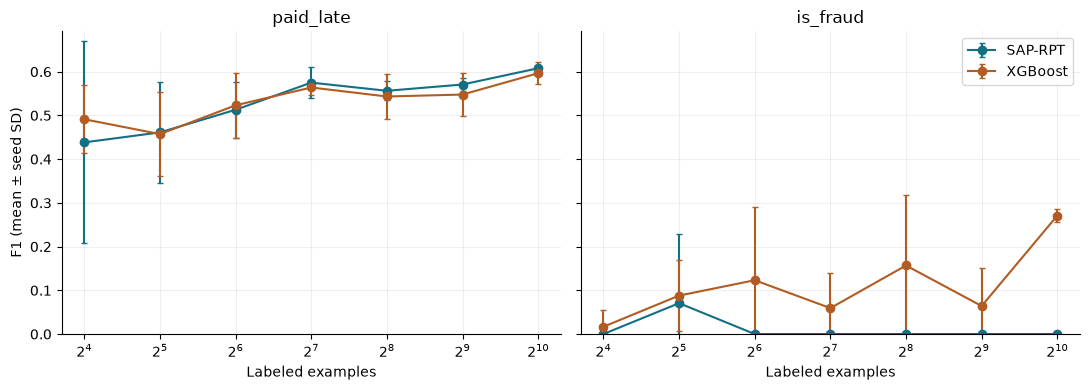

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11,4), sharey=True)
for ax, target in zip(axes, ['paid_late','is_fraud']):
    for model, color in [('SAP-RPT','#136f84'),('XGBoost','#b25b22')]:
        sub = result[(result.target==target)&(result.model==model)].groupby('size').f1.agg(['mean','std'])
        ax.errorbar(sub.index, sub['mean'], yerr=sub['std'].fillna(0), marker='o', capsize=2, label=model, color=color)
    ax.set_xscale('log',base=2); ax.set_title(target); ax.set_xlabel('Labeled examples'); ax.set_ylim(bottom=0); ax.grid(alpha=.2)
axes[0].set_ylabel('F1 (mean ± seed SD)'); axes[1].legend(); plt.tight_layout(); plt.show()

## Takeaways
Read the per-seed table with the chart. Context size changes both the number of labeled examples and, at small budgets, the minority-class count. SAP request latency and XGBoost prediction latency measure different execution paths; XGBoost fitting time is reported separately.